# Module 5 — Notebook 07: cross-cohort summary (exact numbers + main figure)

One uniform rule for every cohort: within fibroblasts, the inflammatory state
is the subcluster (or author label) with the highest mean inflammatory-program
score; we report its share of fibroblasts per condition. Mouse: the DSS-specific
high-program clusters combined. Plus the LIANA switch table assembled from the
saved result CSVs (Smillie module 1 + Martin nb05/05b).

Outputs: `../results/cross_cohort_summary.csv` and
`../figures/cross_cohort_iaf_share.png` — the paper's main figure data.

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt

PROG = ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5"]
rows = []

def program_score(ad, genes):
    genes = [g for g in genes if g in ad.var_names]
    sc.tl.score_genes(ad, genes, score_name="_prog")
    return ad.obs["_prog"]

def share_in_group(obs, group_mask, state_mask, cond_col, conds):
    out = {}
    for c in conds:
        m = group_mask & (obs[cond_col] == c)
        out[c] = float(state_mask[m].mean()) if m.sum() else np.nan
    return out


In [2]:
# --- Smillie (module 1): author labels, fibroblasts = Stromal compartment
p = os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad")
sm = sc.read_h5ad(p)
if "condition" not in sm.obs.columns:
    sm.obs = sm.obs.rename(columns={"Health": "condition", "Cluster": "author_label"})
sm.obs["_prog_all"] = program_score(sm, PROG)
strom = sm.obs["Major_l1"] == "Stromal"
lab_mean = sm.obs[strom].groupby("author_label")["_prog_all"].mean()
iaf_label = lab_mean.idxmax()
print("Smillie IAF label:", iaf_label)
sh = share_in_group(sm.obs, strom, sm.obs["author_label"] == iaf_label, "condition",
                    ["Healthy", "Non-inflamed", "Inflamed"])
rows.append({"cohort": "Smillie UC", "state": iaf_label, **sh})
print(sh)
# Inflammatory monocytes within myeloid, same uniform idea
mye = sm.obs["Major_l1"] == "Myeloid"
lab_m = sm.obs[mye].groupby("author_label")["_prog_all"].mean()
print("Smillie myeloid label program means (top3):"); print(lab_m.sort_values(ascending=False).head(3))


Smillie IAF label: Inflammatory Fibroblasts
{'Healthy': 0.0023584905660377358, 'Non-inflamed': 0.07078634562633343, 'Inflamed': 0.12899755501222493}
Smillie myeloid label program means (top3):
author_label
Best4+ Enterocytes      NaN
CD4+ Activated Fos-hi   NaN
CD4+ Activated Fos-lo   NaN
Name: _prog_all, dtype: float64


In [3]:
# --- Kinchen human: fibroblast object from nb02
p = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018/adata_kinchen_fibroblast.h5ad")
kf = sc.read_h5ad(p)
if "infl_fib_score" not in kf.obs.columns:
    kf.obs["infl_fib_score"] = program_score(kf, PROG)
top = kf.obs.groupby("fib_leiden")["infl_fib_score"].mean().idxmax()
print("Kinchen IAF subcluster:", top)
sh = share_in_group(kf.obs, pd.Series(True, index=kf.obs.index), kf.obs["fib_leiden"] == top,
                    "condition", ["Healthy", "UC"])
rows.append({"cohort": "Kinchen UC", "state": f"fib subcluster {top}", **sh})
print(sh)


Kinchen IAF subcluster: 6
{'Healthy': 0.0002736726874657909, 'UC': 0.1393670183231538}


In [4]:
# --- Martin: fibroblast object from nb04 (IAF = 7; CHI3L1 = 6/15/3)
p = os.path.expanduser("~/Documents/immune-endotypes/data/martin_2019/adata_martin_fibroblast.h5ad")
mf = sc.read_h5ad(p)
allf = pd.Series(True, index=mf.obs.index)
for name, labs in [("IAF (7)", ["7"]), ("CHI3L1-high (6/15/3)", ["6", "15", "3"]),
                   ("IAF + CHI3L1", ["7", "6", "15", "3"])]:
    sh = share_in_group(mf.obs, allf, mf.obs["fib_leiden"].astype(str).isin(labs),
                        "condition", ["Uninvolved", "Involved"])
    rows.append({"cohort": "Martin CD", "state": name, **sh})
    print(name, sh)


IAF (7) {'Uninvolved': 0.0006234413965087282, 'Involved': 0.11061285500747384}
CHI3L1-high (6/15/3) {'Uninvolved': 0.0012468827930174563, 'Involved': 0.3325859491778774}
IAF + CHI3L1 {'Uninvolved': 0.0018703241895261845, 'Involved': 0.4431988041853513}


In [5]:
# --- Kinchen mouse: high-program DSS-specific clusters from nb06
p = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018/adata_kinchen_mouse_qc.h5ad")
ms = sc.read_h5ad(p)
PROG_M = ["Il11", "Il13ra2", "Il24", "Chi3l1", "Mmp3", "Mmp10", "Il6", "Cxcl1", "Cxcl5"]
ms.obs["_prog_all"] = program_score(ms, PROG_M)
ms.obs["_c"] = np.asarray((ms[:, "Col1a1"].X > 0).todense()).ravel() if sp.issparse(ms.X) else np.asarray(ms[:, "Col1a1"].X).ravel() > 0
fc = ms.obs.groupby("leiden_0.5")["_c"].mean() > 0.5
fib_mask = ms.obs["leiden_0.5"].isin(list(fc[fc].index))
fibm = ms.obs[fib_mask]
cm = fibm.groupby("leiden_0.5")["_prog_all"].mean()
hi = list(cm[cm > 0.5].index)
print("mouse high-program fibroblast clusters:", hi, dict(cm.round(2)))
sh = share_in_group(ms.obs, fib_mask, ms.obs["leiden_0.5"].isin(hi), "condition", ["Healthy", "DSS"])
rows.append({"cohort": "Kinchen mouse DSS", "state": "high-program clusters " + ",".join(hi), **sh})
print(sh)


mouse high-program fibroblast clusters: ['1', '2', '6', '7'] {'0': 0.2, '1': 1.01, '2': 1.02, '3': -0.01, '4': 0.02, '5': -0.06, '6': 0.79, '7': 0.51, '8': -0.27, '9': nan, '10': 0.14, '11': nan, '12': 0.47, '13': nan}
{'Healthy': 0.0, 'DSS': 0.7382449835280024}


           cohort                         state  Healthy  Non-inflamed  Inflamed       UC  Uninvolved  Involved      DSS
       Smillie UC      Inflammatory Fibroblasts 0.002358      0.070786  0.128998      NaN         NaN       NaN      NaN
       Kinchen UC              fib subcluster 6 0.000274           NaN       NaN 0.139367         NaN       NaN      NaN
        Martin CD                       IAF (7)      NaN           NaN       NaN      NaN    0.000623  0.110613      NaN
        Martin CD          CHI3L1-high (6/15/3)      NaN           NaN       NaN      NaN    0.001247  0.332586      NaN
        Martin CD                  IAF + CHI3L1      NaN           NaN       NaN      NaN    0.001870  0.443199      NaN
Kinchen mouse DSS high-program clusters 1,2,6,7 0.000000           NaN       NaN      NaN         NaN       NaN 0.738245


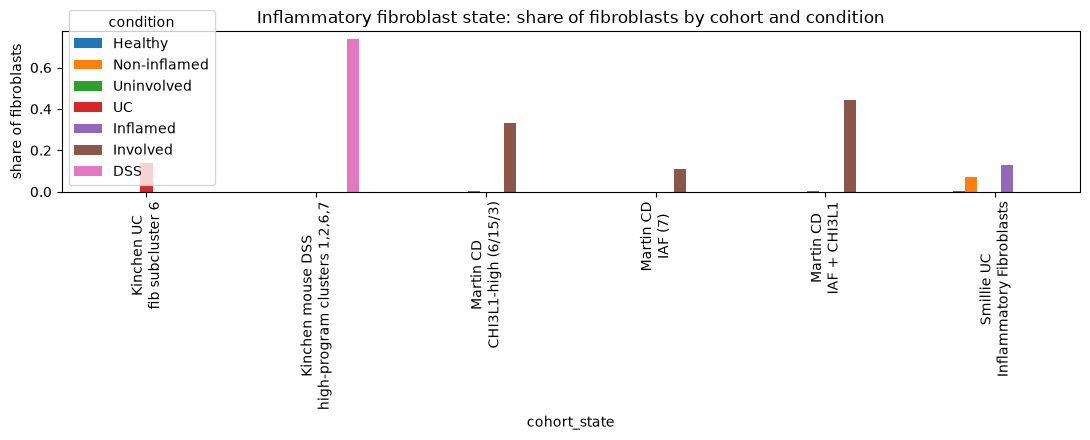

saved ../results/cross_cohort_summary.csv and ../figures/cross_cohort_iaf_share.png


In [6]:
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv("../results/cross_cohort_summary.csv", index=False)

# Main figure: inflammatory-fibroblast share of fibroblasts, grouped bars
plot_rows = []
for _, r in summary.iterrows():
    for cond in ["Healthy", "Non-inflamed", "Inflamed", "UC", "Uninvolved", "Involved", "DSS"]:
        if cond in r and pd.notna(r[cond]):
            plot_rows.append({"cohort_state": f"{r['cohort']}\n{r['state']}", "condition": cond, "share": r[cond]})
pr = pd.DataFrame(plot_rows)
piv = pr.pivot_table(index="cohort_state", columns="condition", values="share")
order = ["Healthy", "Non-inflamed", "Uninvolved", "UC", "Inflamed", "Involved", "DSS"]
piv = piv[[c for c in order if c in piv.columns]]
ax = piv.plot(kind="bar", figsize=(11, 4.5))
ax.set_ylabel("share of fibroblasts")
ax.set_title("Inflammatory fibroblast state: share of fibroblasts by cohort and condition")
plt.tight_layout(); plt.savefig("../figures/cross_cohort_iaf_share.png", dpi=130); plt.show()
print("saved ../results/cross_cohort_summary.csv and ../figures/cross_cohort_iaf_share.png")


In [7]:
# LIANA switch table assembled from saved CSVs (run if the files exist)
import glob
for f in sorted(glob.glob(os.path.expanduser("~/Documents/immune-endotypes/results/liana_res_*.csv"))) + \
         sorted(glob.glob("../results/liana_martin_*.csv")):
    print(f)
print("Assemble the final switch table in the manuscript draft from:")
print("- Smillie (module 1 nb04): OSM-OSMR 0.00 -> 1.06 -> 1.16; IL11-IL11RA inflamed-only 2.24; IL1B-SIGIRR 20.49 -> 10.45 -> 5.88")
print("- Martin nb05: OSM-OSMR 0.00 -> 1.43 (Myeloid->Fibroblast); nb05b: -> Fib_CHI3L1 2.39; IL1B-SIGIRR 2.66 vs 3.02 (no gradient)")


../results/liana_martin_Involved.csv
../results/liana_martin_Uninvolved.csv
../results/liana_martin_fib_Involved.csv
../results/liana_martin_fib_Uninvolved.csv
Assemble the final switch table in the manuscript draft from:
- Smillie (module 1 nb04): OSM-OSMR 0.00 -> 1.06 -> 1.16; IL11-IL11RA inflamed-only 2.24; IL1B-SIGIRR 20.49 -> 10.45 -> 5.88
- Martin nb05: OSM-OSMR 0.00 -> 1.43 (Myeloid->Fibroblast); nb05b: -> Fib_CHI3L1 2.39; IL1B-SIGIRR 2.66 vs 3.02 (no gradient)


## Read-out

The summary CSV + bar figure are the paper's quantitative spine. Remaining
work: the manuscript draft (title page, abstract, results in cohort order,
methods with the recorded caveats, discussion that cites scIBD / Gut Cell
Atlas / Friedrich 2021 / Biology Direct fibroblast paper as predecessors
without claiming their ground).
